# Correlation between affinity and binding scores for c259 TCR binding peptide mutants

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr

In [2]:
sequences = pd.read_csv('../data/interim/sequences_c259_mutational_scan_affinity.csv', index_col='id')

In [3]:
sequences['geometric_mean'] = sequences['geometric_mean'].fillna(np.inf)
sequences['affinity_norm'] = sequences['geometric_mean'].min() / sequences['geometric_mean']

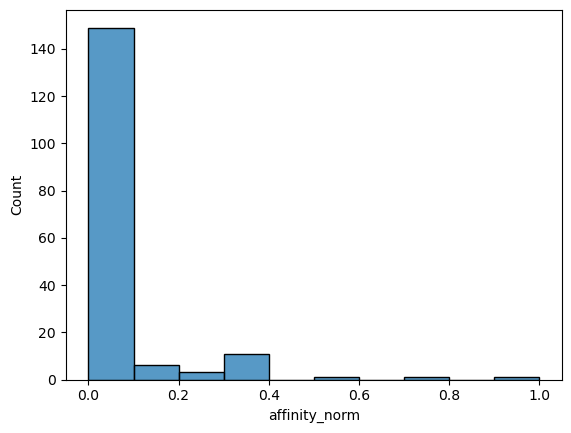

In [4]:
sns.histplot(sequences, x='affinity_norm', bins=10)
plt.show()

In [5]:
binding_scores = pd.read_csv(
    '../data/processed/af3_af3_tcrmodel2_c259_mutational_scan_affinity_pae_aggregator_predictions.csv'
)
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

binding_scores = binding_scores.merge(sequences, how='inner', left_on='name', right_index=True)

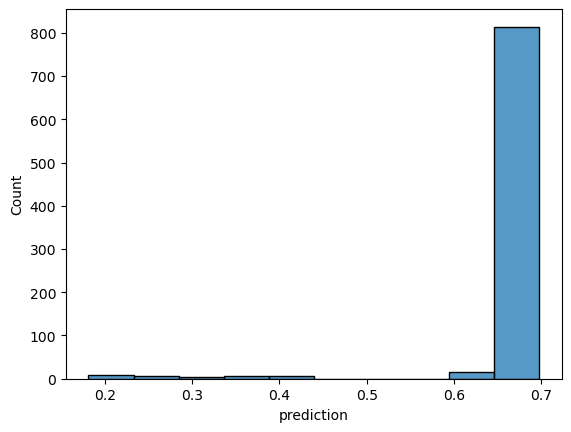

In [6]:
sns.histplot(binding_scores, x='prediction', bins=10)
plt.show()

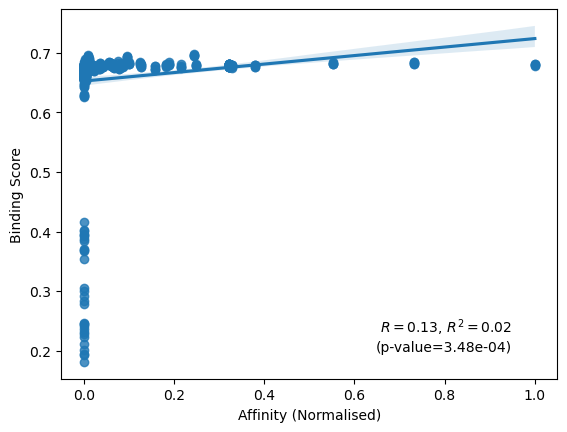

In [7]:
ax = sns.regplot(binding_scores[~np.isinf(binding_scores['geometric_mean'])], x='affinity_norm', y='prediction')

r, p_val = pearsonr(
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'affinity_norm'],
    binding_scores.loc[~np.isinf(binding_scores['geometric_mean']), 'prediction'],
    alternative='greater',
)
ax.text(0.95, 0.2, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')

plt.show()

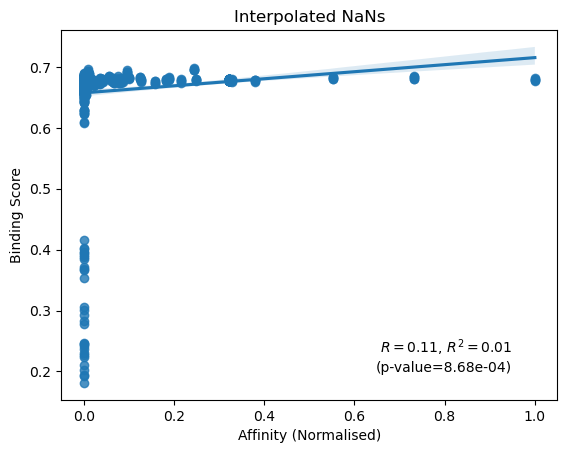

In [8]:
ax = sns.regplot(binding_scores, x='affinity_norm', y='prediction')

r, p_val = pearsonr(binding_scores['affinity_norm'], binding_scores['prediction'], alternative='greater')
ax.text(0.95, 0.2, f'$R={r:.2f}$, $R^2={r**2:.2f}$\n(p-value={p_val:.2e})', ha='right')

ax.set_ylabel('Binding Score')
ax.set_xlabel('Affinity (Normalised)')
ax.set_title('Interpolated NaNs')

plt.show()